In [1]:
from astropy.io import fits
from astropy.visualization import ZScaleInterval
from pprint import pprint as pp
import numpy as np
import cmastro
import matplotlib.pyplot as plt
from scipy.ndimage import label
import pandas as pd
import seaborn as sns

#import seaborn as sns
sns.set_theme(context='paper', style='ticks', font_scale=1.5, font='serif', palette='deep', color_codes=True)
plt.rcParams['image.origin'] = 'lower'
plt.rcParams['figure.figsize'] = (12,6)

Get all the .fts files and sort them

In [2]:
from fileinput import filename
filenames = np.loadtxt('Lab5_ACAM_DATA/filelist', dtype=str, usecols=0)
flats = []
flats_hdu = []
biases = []
biases_hdu = []
science = []
science_hdu = []
for f in filenames:
    file = fits.open(r'Lab5_ACAM_DATA/' + f)
    header = file[0].header
    if header['OBSTYPE'] == 'FLAT':
        # print("-------")
        # print("File Name: ", f)
        # print("Image Type: ", header['OBSTYPE'])
        # print("Image Dimensions: ", file[1].data.shape)
        flats.append(file[1].data)
        flats_hdu.append(file[0].header)
    elif header['OBSTYPE'] == 'BIAS':
        if file[1].shape == (2071, 2148):
            # print("-------")
            # print("File Name: ", f)
            # print("Image Type: ", header['OBSTYPE'])
            # print("Instrument: ", header['INSTRUME'])
            # print("Exposure Time: ", header['EXPTIME'])
            # print("Image Dimensions: ", file[1].data.shape)
            biases.append(file[1].data)
            biases_hdu.append(file[0].header)
    elif header['OBSTYPE'] == 'TARGET':
        # print("-------")
        # print("File Name: ", f)
        # print("Image Type: ", header['OBSTYPE'])
        # print("Instrument: ", header['INSTRUME'])
        # print("Exposure Time: ", header['EXPTIME'])
        # print("Image Dimensions: ", file[1].data.shape)
        science.append(file[1].data)
        science_hdu.append(file[0].header)
        
science_np = np.array(science)
flats_np = np.array(flats)
biases_np = np.array(biases)

In [3]:
# Create mask for region outside vignette
threshold = 13000
mask = np.where(flats_np[0] > threshold, True, False)

# Normalize by exp time
for i in range(len(flats)):
    flats_np[i] = flats_np[i] * mask
    flats_np[i] = flats_np[i] / flats_hdu[i]['EXPTIME']
for i in range(len(science)):
    science_np[i] = science_np[i] * mask
    science_np[i] = science_np[i] / science_hdu[i]['EXPTIME']
    
# Median bias and flats
median_bias = np.median(biases_np*mask, axis=0)
median_flat = np.median(flats_np, axis=0)
median_flat = median_flat / np.median(median_flat)
median_bias = median_bias / np.median(median_bias)
    
# for i in range(len(biases)):
#     biases_np[i] = biases_np[i] * mask


(364, 2071, 2148)


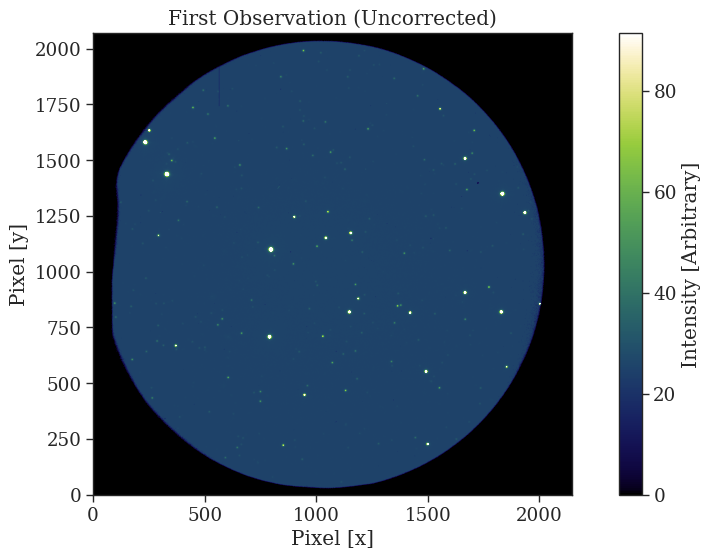

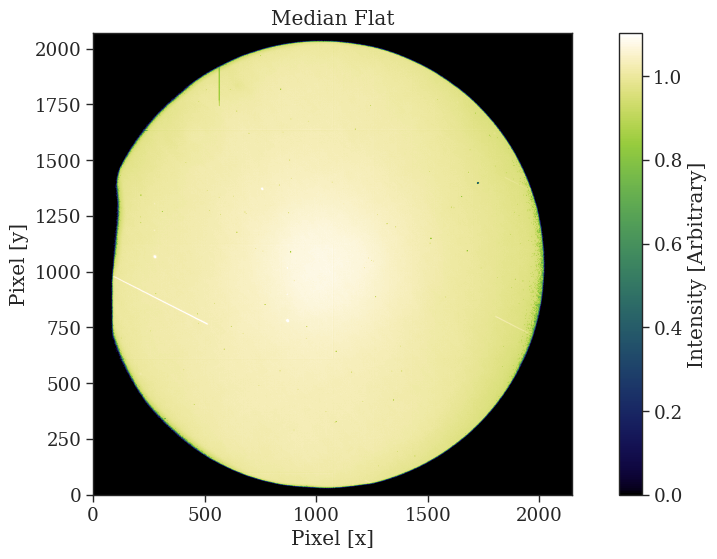

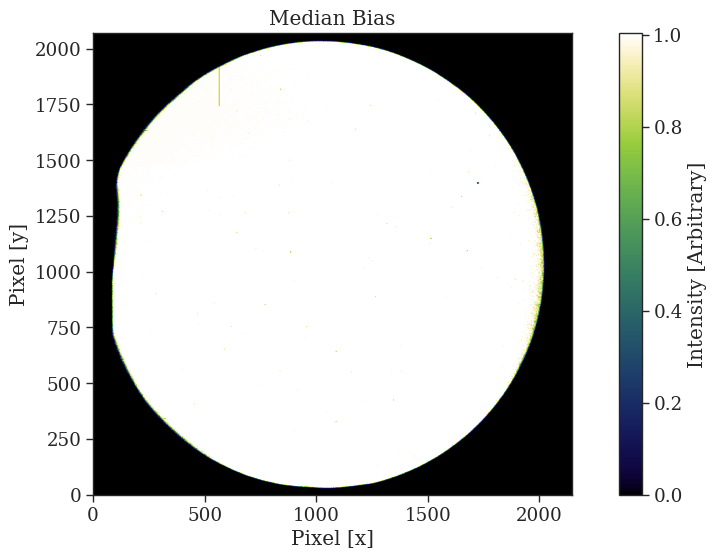

In [4]:
vmin, vmax = ZScaleInterval().get_limits(science_np[0])
plt.imshow(science_np[0], cmap='cma:lacerta', vmin=vmin, vmax=vmax)
plt.title("First Observation (Uncorrected)")
plt.xlabel("Pixel [x]")
plt.ylabel("Pixel [y]")
plt.colorbar(label="Intensity [Arbitrary]")
plt.show()

plt.title("Median Flat")
vmin, vmax = ZScaleInterval().get_limits(median_flat)
plt.imshow(median_flat, cmap='cma:lacerta', vmin=vmin, vmax=vmax)
plt.xlabel("Pixel [x]")
plt.ylabel("Pixel [y]")
plt.colorbar(label='Intensity [Arbitrary]')
plt.show()

plt.title("Median Bias")
vmin, vmax = ZScaleInterval().get_limits(median_bias)
plt.imshow(median_bias, cmap='cma:lacerta', vmin=vmin, vmax=vmax)
plt.xlabel("Pixel [x]")
plt.ylabel("Pixel [y]")
plt.colorbar(label='Intensity [Arbitrary]')
plt.show()

In [5]:
for i in range(len(science_np)):
    science_np[i] = science_np[i] - (median_bias)
    science_np[i] = science_np[i] / median_flat

C:\Users\lwrig\AppData\Local\Temp\ipykernel_3192\261379300.py:8: RuntimeWarning: invalid value encountered in divide
  science_np[i] = science_np[i] / median_flat
C:\Users\lwrig\AppData\Local\Temp\ipykernel_3192\261379300.py:8: RuntimeWarning: invalid value encountered in cast
  science_np[i] = science_np[i] / median_flat


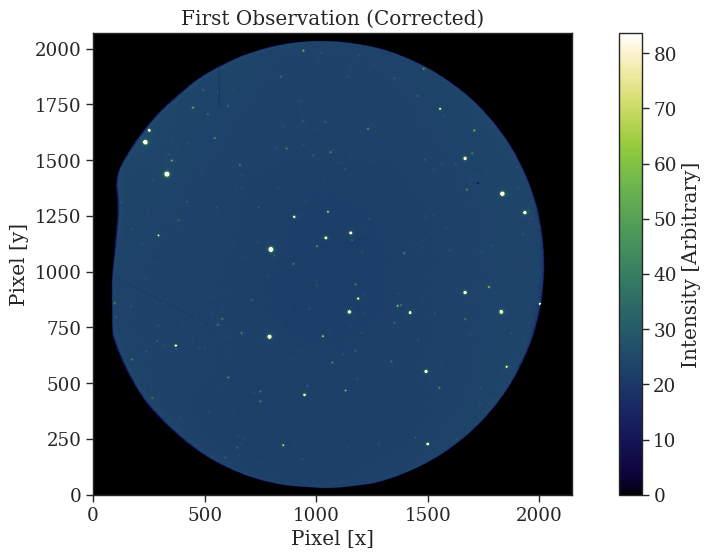

In [6]:
fig = plt.figure(figsize=(12,6))
plt.title("First Observation (Corrected)")
vmin, vmax = ZScaleInterval().get_limits(science_np[0])
plt.imshow(science_np[0], cmap='cma:lacerta', vmin=vmin, vmax=vmax)
plt.xlabel("Pixel [x]")
plt.ylabel("Pixel [y]")
plt.colorbar(label='Intensity [Arbitrary]')
plt.savefig('plt/science_img.pdf')
plt.show()    

In [7]:
from scipy.optimize import curve_fit

def star_gaussian(stars, image, size=10, filter=False): 
    uncertainties = []   
    centroids_x_coords = []
    centroids_y_coords = []
    initial_cen_x = []
    initial_cen_y = []
    app_radiuses = []

    failed_fittings = 0
    size = size
    
    # 2d gaussian
    def gauss(xy, a, x0, y0, sigma_x, sigma_y, c):
        x, y = xy
        g = a*np.exp(-(x-x0)**2/(2*sigma_x**2) - (y-y0)**2/(2*sigma_y**2)) + c
        return g.ravel()

    for i in range(len(stars[0])):
        box = image[int(stars[1][i])-size:int(stars[1][i])+size, int(stars[0][i])-size:int(stars[0][i])+size]
        
        # Create coordinate matrices and flatten them for fitting
        xx, yy = np.meshgrid(np.arange(box.shape[1]), np.arange(box.shape[0])) 
        xx_flat = xx.ravel()
        yy_flat = yy.ravel()

        # Use centroid equation for initial guess
        x = np.sum(xx * box) / np.sum(box) 
        y = np.sum(yy * box) / np.sum(box) 
        # Fit Gaussian
        if len(yy_flat) != 0:            
            try:
                initial_guess = (250,x,y,size/2,size/2,0)
                popt, pcov = curve_fit(gauss, (xx_flat, yy_flat), box.ravel(), p0=initial_guess, nan_policy='omit')
                if filter:
                    if np.max(np.sqrt(np.diag(pcov))) < 0.0125:
                            
                        # get new centroid
                        centroid_x, centroid_y = popt[1], popt[2]
                        
                        # put the coords back in the original context of the image
                        x = stars[0][i] - size + x
                        y = stars[1][i] - size + y
                        
                        centroid_x = stars[0][i] - size + centroid_x
                        centroid_y = stars[1][i] - size + centroid_y
                        
                        # print(f"Initial Coordinate: {stars[0][i]}, {stars[1][i]}")
                        # print(f"Inital Centroid: {x}, {y}")
                        # print(f"Gaussian Centroid: {centroid_x}, {centroid_y}")
                        
                        # add centroids to list of coords
                        initial_cen_x.append(x)
                        initial_cen_y.append(y)
                        centroids_x_coords.append(centroid_x)
                        centroids_y_coords.append(centroid_y)
                        uncertainties.append(np.max(np.sqrt(np.diag(pcov))))
                else:
                    centroid_x, centroid_y = popt[1], popt[2]
                    # put the coords back in the original context of the image
                    x = stars[0][i] - size + x
                    y = stars[1][i] - size + y
                    
                    centroid_x = stars[0][i] - size + centroid_x
                    centroid_y = stars[1][i] - size + centroid_y
                    
                    app_radiuses.append(max(3*np.abs(popt[4]), 3*np.abs(popt[3]))) # Use maximum of 3-sigma in x or y                     
                    
                    # print(f"Initial Coordinate: {stars[0][i]}, {stars[1][i]}")
                    # print(f"Inital Centroid: {x}, {y}")
                    # print(f"Gaussian Centroid: {centroid_x}, {centroid_y}")
                    
                    # add centroids to list of coords
                    initial_cen_x.append(x)
                    initial_cen_y.append(y)
                    centroids_x_coords.append(centroid_x)
                    centroids_y_coords.append(centroid_y)
                    uncertainties.append(np.max(np.sqrt(np.diag(pcov))))
                
            except RuntimeError:
                failed_fittings += 1
    # print(f"Fit {len(centroids_x_coords)} stars")
    # print(f"Couldn't fit {failed_fittings} stars")
    #print("Radius: ", app_radius)
    return centroids_x_coords, centroids_y_coords, initial_cen_x, initial_cen_y, uncertainties, app_radiuses

# Track star throughout the observations to approximate global displacement
stars_x = [790]
stars_y = [710]
box=40

# vmin,vmax = ZScaleInterval().get_limits(science_np[0])
# plt.imshow(science_np[0], cmap='cma:lacerta', vmin=vmin,vmax=vmax)
# plt.scatter(stars_x, stars_y, c='r', s=5)
# plt.xlim(stars_x[0]-box, stars_x[0]+box)
# plt.ylim(stars_y[0]-box, stars_y[0]+box)
# plt.show()

centroid_x = []
centroid_y = []
approx_x = []
approx_y = []
uncertainties = []

for i in range(len(science_np)):
    x, y, cen_x, cen_y, uncertainties, _ = star_gaussian([stars_x,stars_y], science_np[i], size=box, filter=False) 
    centroid_x.append(x)
    centroid_y.append(y)
    approx_x.append(cen_x)
    approx_y.append(cen_y)
    uncertainties.append(uncertainties)
    if (len(x) == 0) or (len(y) == 0):
        print(f"Failed to find star in image {i}")
        


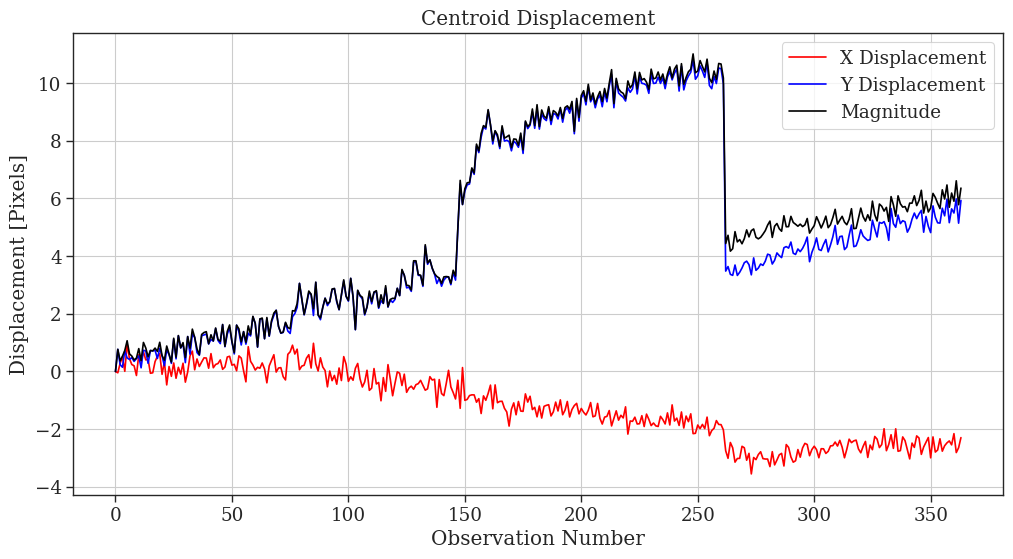

In [8]:
# for i, element in enumerate(centroid_x):
#     if len(element) != 1:
#         print(f"At index {i}, missing centroid")
        
x_motion = np.array([centroid_x[i][0] - centroid_x[0][0] for i in range(len(centroid_x))])
y_motion = np.array([centroid_y[i][0] - centroid_y[0][0] for i in range(len(centroid_y))])
magnitude = np.sqrt(x_motion**2 + y_motion**2)
fig = plt.figure(figsize=(12,6))
plt.title("Centroid Displacement")
plt.xlabel("Observation Number")
plt.ylabel("Displacement [Pixels]")
plt.plot(np.arange(0,len(x_motion)),x_motion, label='X Displacement', color="red")
plt.plot(np.arange(0,len(y_motion)),y_motion, label='Y Displacement', color="blue")
plt.plot(np.arange(0,len(magnitude)),magnitude, label='Magnitude', color="black")
plt.legend()
plt.grid()
plt.show()
fig.savefig('plt/centroid_displacement.pdf')    


In [9]:
x, y = [1130],[470] # A new star to check our work
x, y, _, _, _ , rad = star_gaussian([x,y], science_np[0], size=box, filter=False)

centroid2_x = []
centroid2_y = []
centroid2_uncertainties = []

box = 20 

# Check all the images to make sure it's lining up nicely :) 
# for i in range(len(science_np)):
#     new_x = int(np.round(x + x_motion[i]))
#     new_y = int(np.round(y + y_motion[i]))
#     centroid2_x.append(new_x)
#     centroid2_y.append(new_y)
#     centroid2_uncertainties.append(uncertainties)
#     vmin,vmax = ZScaleInterval().get_limits(science_np[i])
#     plt.imshow(science_np[i], cmap='cma:lacerta', vmin=vmin,vmax=vmax)
#     plt.scatter(new_x, new_y, c='r', s=5)
#     plt.xlim(new_x-box, new_x+box)
#     plt.ylim(new_y-box, new_y+box)
#     plt.show()   

Found 34 stars


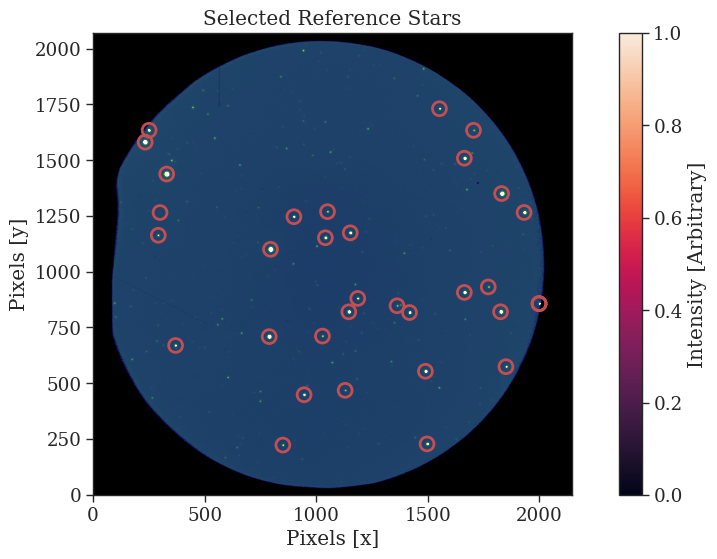

2274


In [23]:
threshold = 85
stars_x = []
stars_y = []
aperture_radius = []

# Find parts of img where intensity > threshold
binary_img = np.where(science_np[0] > threshold, 1, 0)

# Assign each star region a different integer
star_labels, num_stars = label(binary_img)
print(f"Found {num_stars} stars")

# Loop through each region and pick a single point to feed the centroider.
for i in range(1,num_stars+1):
    region_coords = np.where(star_labels == i)
    # Use middle point in each region
    middle_x = np.mean(region_coords[0]).astype(int)
    middle_y = np.mean(region_coords[1]).astype(int) 
    stars_x.append(middle_y)
    stars_y.append(middle_x)
    
size=15
centroid_x, centroid_y, init_x, init_y, position_uncertainties, rad = star_gaussian([stars_x, stars_y], science_np[0], size=size)
centroid_catalog = pd.DataFrame({'centroid_x': centroid_x, 'centroid_y': centroid_y, 'aperture_radius': rad})

# Save centroids
centroid_catalog.to_csv('centroid_catalog.csv')


### For removing bad stars
# centroid_catalog = centroid_catalog.drop([0,5,17,19])
# centroid_catalog = centroid_catalog.reset_index(drop=True)

# ## Check the centroids individually
# vmin, vmax = ZScaleInterval().get_limits(science_np[0])
# for i in range(len(centroid_catalog)):
#     plt.title(f"Reference {i}")
#     plt.imshow(science_np[0], cmap='cma:lacerta', vmin=vmin,vmax=vmax)
#     plt.scatter(centroid_catalog['centroid_x'], centroid_catalog['centroid_y'], c='r', s=40, label="Gaussian Centroid", marker='x')
#     plt.scatter(init_x,init_y, c='b', s=40, label="Traditional Centroid", marker='x')
#     plt.xlim(centroid_catalog['centroid_x'][i]-size, centroid_catalog['centroid_x'][i]+size)
#     plt.ylim(centroid_catalog['centroid_y'][i]-size, centroid_catalog['centroid_y'][i]+size)
#     plt.legend()
#     plt.show()

# Check whole image w/ centroids
fig = plt.figure(figsize=(12,6))
plt.imshow(science_np[0], cmap='cma:lacerta', vmin=vmin,vmax=vmax)
plt.scatter(centroid_catalog['centroid_x'], centroid_catalog['centroid_y'], s=100, facecolors='none', edgecolors='r',lw=2)
plt.title("Selected Reference Stars")
plt.xlabel("Pixels [x]")
plt.ylabel("Pixels [y]")
plt.colorbar(label="Intensity [Arbitrary]")
fig.savefig('plt/selected_reference_stars.pdf')
plt.show()

######## TARGET STAR ########
target_approx_x = 1419
target_approx_y = 817
target_centroid_x, target_centroid_y, _, _, _, target_rad = star_gaussian([np.array([target_approx_x]), np.array([target_approx_y])], science_np[0], size=8, filter=False)
size = 650

# for i in range(len(science_np)):
#     plt.imshow(science_np[i], cmap='cma:lacerta', vmin=vmin,vmax=vmax)
#     xcenter = target_centroid_x[0] + x_motion[i]
#     ycenter = target_centroid_y[0] + y_motion[i]
#     plt.scatter(xcenter,ycenter, c='r', s=2)
#     plt.xlim(xcenter-size, xcenter+size)
#     plt.ylim(ycenter-size, ycenter+size)
#     plt.show()
##############################

Now to get flux curves of these stars

In [49]:
gain = 4 # e/DN
def aperture_photometry(image, x, y, xcenter, ycenter, app_radius, inner_radius, outer_radius, plot=False):
    def annulus():
        r_squared = (x - xcenter)**2 + (y - ycenter)**2
        mask = (r_squared <= outer_radius**2) & (r_squared >= inner_radius**2)
        annulus_sum = np.sum(image * mask)
        num_pixels = np.sum(mask)
        level_per_pixel = annulus_sum / num_pixels
        
        # Uncertainty
        sigma_bg = np.std(image*mask)

        if plot:
            plt.xlim(xcenter-20,xcenter+20)
            plt.ylim(ycenter-20,ycenter+20)
            vmin,vmax = ZScaleInterval().get_limits(image)
            plt.imshow(image, vmin=-vmin, vmax = vmax, origin='lower', cmap='cma:lacerta')
            plt.imshow(mask, origin='lower', cmap='gray', alpha=0.6)
            plt.savefig("plt/annulus.pdf")
            plt.show()
        return level_per_pixel, sigma_bg
    
    def aperture():
        mask = ((x - xcenter)**2 + (y - ycenter)**2) <= app_radius**2
        aperture_sum = np.sum(image * mask)
        if plot:
            plt.xlim(xcenter-20,xcenter+20)
            plt.ylim(ycenter-20,ycenter+20)
            vmin,vmax = ZScaleInterval().get_limits(image)
            plt.imshow(image, vmin=vmin, vmax = vmax, origin='lower', cmap='cma:lacerta')
            plt.imshow(mask, origin='lower', cmap='inferno', alpha=0.6)
            plt.savefig("plt/aperture.pdf")
        plt.show()
        return aperture_sum, mask
    
    def uncertainty(flux,sigma_bg,num_aperture,num_annulus):
        return np.sqrt(flux/gain + num_aperture*(1+(np.pi*num_aperture)/(2*num_annulus)*sigma_bg**2))

    flux = aperture()[0] - annulus()[0]
    error = uncertainty(flux, annulus()[1], np.sum(aperture()[1]), np.sum(annulus()[1]))
    return flux, error

def process_observation(i, j=0):
    xcenter = centroid_catalog['centroid_x'][j] + x_motion[i]
    ycenter = centroid_catalog['centroid_y'][j] + y_motion[i]
    inner_radius = centroid_catalog['aperture_radius'][j] + 6
    outer_radius = centroid_catalog['aperture_radius'][j] + 14
    app_radius = centroid_catalog['aperture_radius'][j]
    flux, flux_uncertainty = aperture_photometry(science_np[i], x, y, xcenter, ycenter, app_radius, 
                                            inner_radius, outer_radius, plot=False)
    return pd.DataFrame({'Observation': [i], 'star_number': [j], 'centroid_x': [xcenter], 
                         'centroid_y': [ycenter], 'flux': [flux], 'uncertainty': [flux_uncertainty]})

# #Uncomment for fresh data

ysize, xsize = science_np[0].shape
y, x = np.mgrid[:ysize, :xsize]
# results = []
# for i in range(len(science_np)):
#     print(f"Observation {i} / {len(science_np)-1}")
#     print("---")
#     for j in range(len(centroid_catalog)):
#         #print("Star ", j)
#         obs = process_observation(i, j)
#         results.append(obs)
# full_df = pd.concat(results)
# full_df.to_csv('flux_database.csv', index=False)

In [51]:
# ### TARGET FLUX #####
# results = []
# for i in range(len(science_np)):
#     xcenter = target_centroid_x[0] + x_motion[i]
#     ycenter = target_centroid_y[0] + y_motion[i]
#     inner_radius = target_rad[0] + 10
#     outer_radius = target_rad[0] + 20
#     flux, flux_uncertainty = aperture_photometry(science_np[i], x, y, xcenter, ycenter, target_rad[0], 
#                                             inner_radius, outer_radius,plot=False)
#     print(f"Observation {i} - Flux: {flux} +/- {flux_uncertainty}")
#     obs = pd.DataFrame({'Observation': [i], 'centroid_x': [xcenter], 
#                          'centroid_y': [ycenter], 'flux': [flux], 'uncertainty': [flux_uncertainty]})
#     results.append(obs)
#target_df = pd.concat(results)
#target_df.to_csv('target_flux_database.csv', index=False)

IndexError: index 4 is out of bounds for axis 0 with size 4

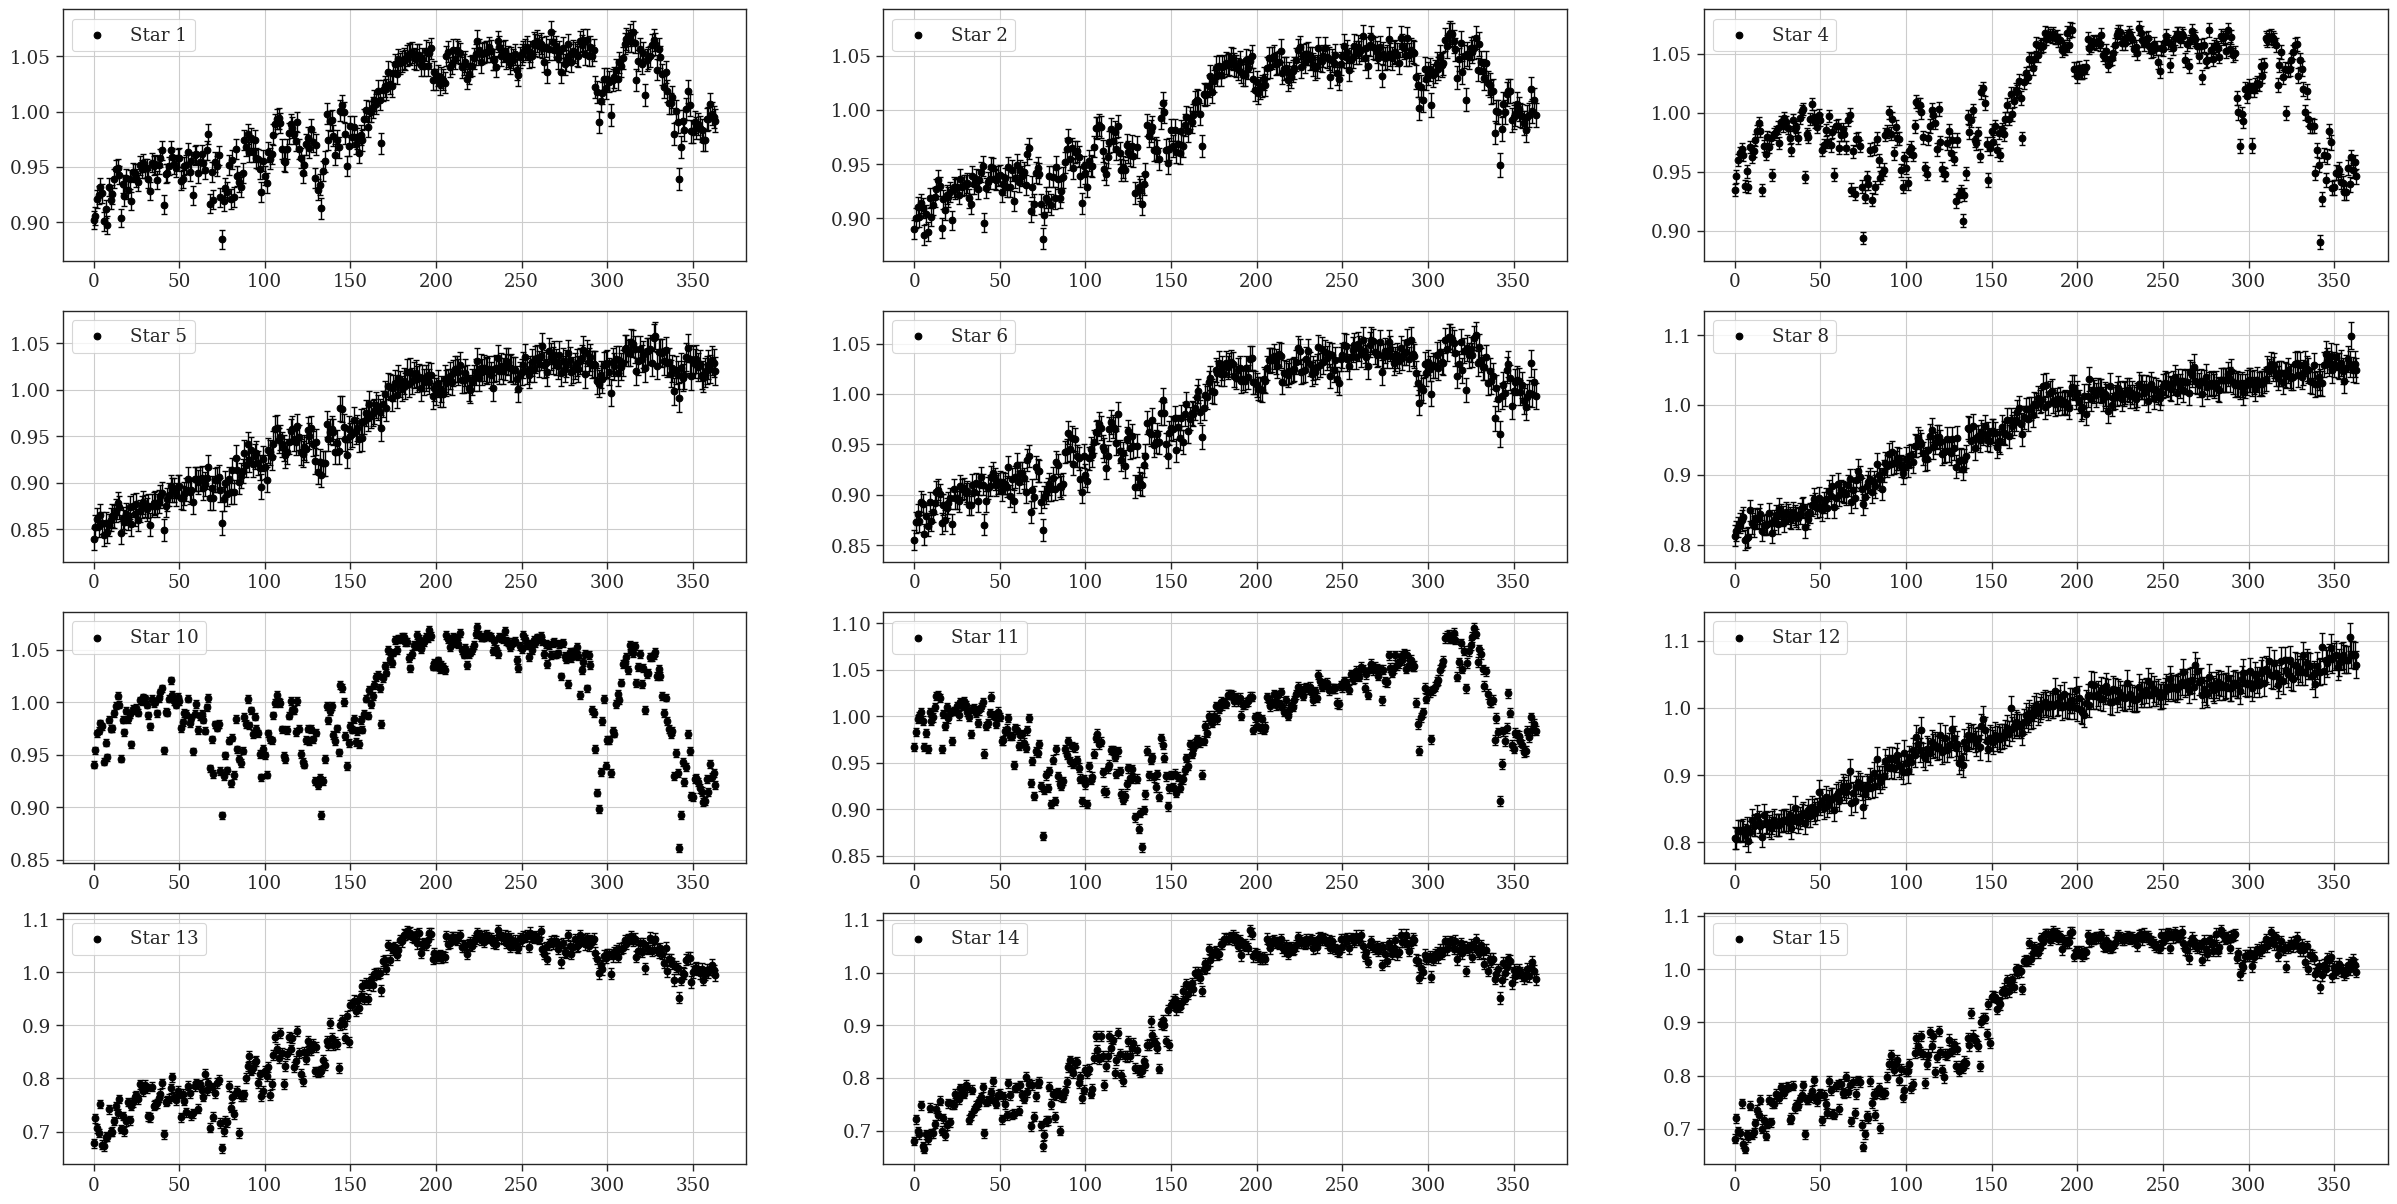

In [241]:
flux_database = pd.read_csv('flux_database.csv')


############ Remove star_number 8 (Transit Star)
flux_database = flux_database[flux_database['star_number'] != 9]

# Compute the median flux of each star
medians = flux_database.groupby('star_number')['flux'].median()

# Divide the fluxes by the median flux of their star
flux_database['norm_flux'] = flux_database.groupby('star_number')['flux'].transform(lambda x: x / medians[x.name])

# Also scale the errors by median flux
flux_database['norm_uncertainty'] = flux_database.groupby('star_number')['uncertainty'].transform(lambda x: x / medians[x.name])

######### Remove any wack curves
flux_database = flux_database[~flux_database['star_number'].isin([7,25,19,28,27,30])]
flux_database = flux_database[~flux_database['star_number'].isin([0,3])] 
#flux_database = flux_database[~flux_database['star_number'].isin([13,14])] 
flux_database = flux_database.reset_index(drop=True)

########## Plot All Curves
# for star in flux_database['star_number'].unique():
#     fig = plt.figure(figsize=(10,4))
#     y_data = flux_database['norm_flux'][flux_database['star_number'] == star]
#     x_data = np.arange(len(y_data))
#     plt.title(f"Star {star} Flux")
#     plt.xlabel("Observation Number")
#     plt.ylabel("Normalized Flux")
#     plt.scatter(x_data, y_data, label=f"Star {star}", color="black")
#     plt.errorbar(x_data, y_data, yerr=flux_database['norm_uncertainty'][flux_database['star_number'] == star], fmt='none', ecolor='black', elinewidth=1, capsize=2)
#     plt.legend()
#     plt.grid()
#     plt.show()


import math
unique_stars = flux_database['star_number'].unique()
n = len(unique_stars)
rows = math.ceil(n/8) 
cols = 3  
fig, axs = plt.subplots(rows, cols, figsize=(30,15)) 
for idx, star in enumerate(unique_stars):
    row = idx // cols
    col = idx % cols
    y_data = flux_database['norm_flux'][flux_database['star_number'] == star]
    x_data = np.arange(len(y_data))
    axs[row, col].scatter(x_data, y_data, label=f"Star {star}", color="black")
    axs[row, col].errorbar(x_data, y_data, yerr=flux_database['norm_uncertainty'][flux_database['star_number'] == star], fmt='none', ecolor='black', elinewidth=1, capsize=2)
    axs[row, col].legend()
    axs[row, col].grid()
fig.tight_layout()
fig.savefig('plt/curves.pdf')
plt.show()
flux_database.head()


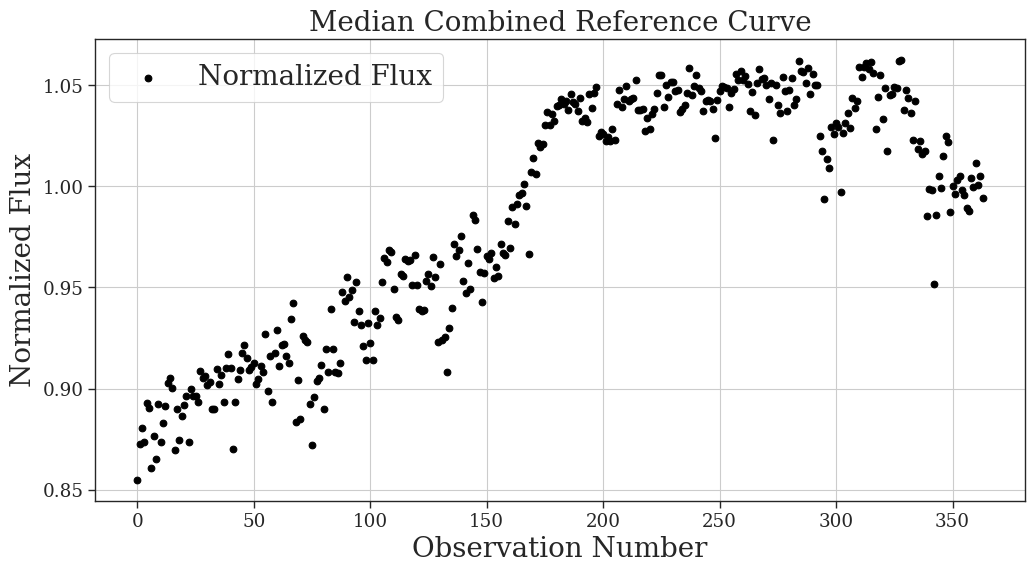

0       14601.727133
1       12202.185196
2       37272.951561
3        6784.367107
4        9566.546428
            ...     
9095     3040.555018
9096    30278.433869
9097    11755.500258
9098     2376.414112
9099     3964.825978
Name: norm_uncertainty, Length: 9100, dtype: float64


C:\Users\lwrig\AppData\Local\Temp\ipykernel_3192\3716190370.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  weighted_mean_reference = flux_database.groupby('Observation').apply(lambda x: np.average(x['norm_flux'], weights=weights[x.index]))
C:\Users\lwrig\AppData\Local\Temp\ipykernel_3192\3716190370.py:23: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  weighted_mean_uncertainty = flux_database.groupby('

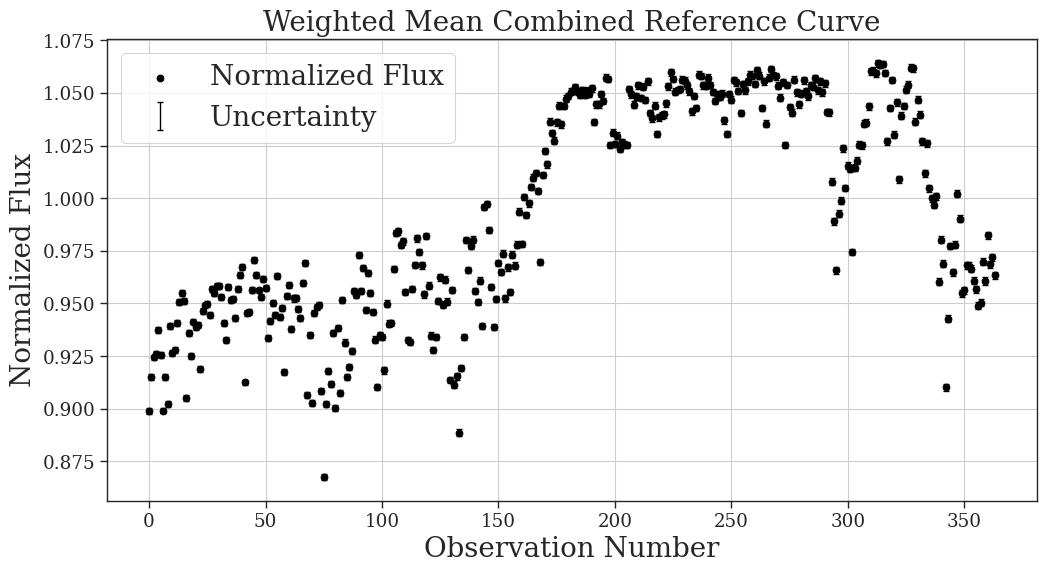

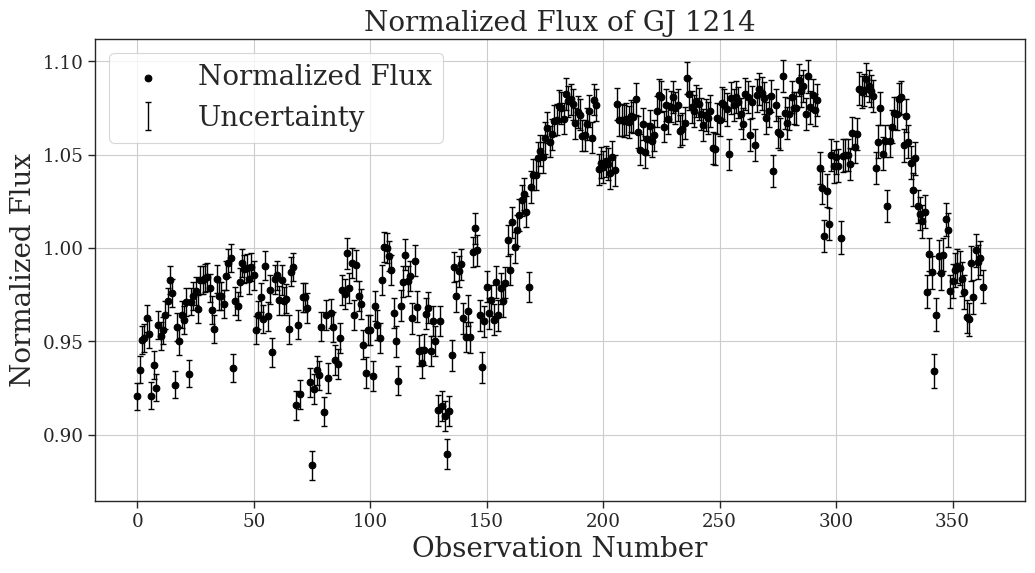

,Observation,centroid_x,centroid_y,flux,uncertainty
0,0,1418.511825,817.160739,17578.377345,140.316311
1,1,1418.465362,817.927427,17850.420217,140.436999
2,2,1418.793525,817.396996,18150.416006,141.448337
3,3,1419.022005,817.307015,18174.274566,142.621024
4,4,1418.517540,817.886850,18373.388286,142.328712


In [53]:
# Compute reference light curves 

plt.rcParams['font.size'] = 16

# Median Reference Curve
median_reference = flux_database.groupby('Observation')['norm_flux'].median()
flux_database['median_reference'] = flux_database['Observation'].map(median_reference)
fig = plt.figure(figsize=(12,6))
plt.title("Median Combined Reference Curve",fontsize=20)
plt.xlabel("Observation Number",fontsize=20)
plt.ylabel("Normalized Flux",fontsize=20)
plt.scatter(np.arange(len(median_reference)), median_reference, color='black', label="Normalized Flux")
plt.legend(fontsize=20)
plt.grid()
plt.show()
fig.savefig('plt/median_reference_curve.pdf')

# Weighted Mean Reference Curve
fig = plt.figure(figsize=(12,6))
weights = 1./flux_database['norm_uncertainty']**2
weighted_mean_reference = flux_database.groupby('Observation').apply(lambda x: np.average(x['norm_flux'], weights=weights[x.index]))
weighted_mean_uncertainty = flux_database.groupby('Observation').apply(lambda x: 1/np.sqrt(np.sum(weights[x.index])))
flux_database['weighted_mean_reference'] = flux_database['Observation'].map(weighted_mean_reference)
plt.title("Weighted Mean Combined Reference Curve",fontsize=20)
plt.xlabel("Observation Number",fontsize=20)
plt.ylabel("Normalized Flux",fontsize=20)
plt.scatter(np.arange(len(weighted_mean_reference)), weighted_mean_reference, color='black', label="Normalized Flux")
plt.errorbar(np.arange(len(weighted_mean_reference)), weighted_mean_reference, yerr=weighted_mean_uncertainty, fmt='none', ecolor='black', elinewidth=1, capsize=2, label="Uncertainty")
plt.grid()
plt.legend(fontsize=20)
plt.show()
fig.savefig('plt/weighted_mean_reference_curve.pdf')


# Median Normalize Target
target_flux = pd.read_csv('target_flux_database.csv')
norm_target_flux = target_flux['flux']/np.median(target_flux['flux'])
norm_target_uncertainty = target_flux['uncertainty']/np.median(target_flux['flux'])


# Plot Target Light Curve
fig = plt.figure(figsize=(12,6))
plt.title("Normalized Flux of GJ 1214",fontsize=20)
plt.xlabel("Observation Number",fontsize=20)
plt.ylabel("Normalized Flux",fontsize=20)
plt.scatter(np.arange(len(norm_target_flux)), norm_target_flux, color='black',label="Normalized Flux")
plt.errorbar(np.arange(len(norm_target_flux)), norm_target_flux, yerr=norm_target_uncertainty, fmt='none', ecolor='black', elinewidth=1, capsize=2,label="Uncertainty")
plt.grid()
plt.legend(fontsize=20)
plt.show()
fig.savefig('plt/target_light_curve.pdf')
target_flux.head()


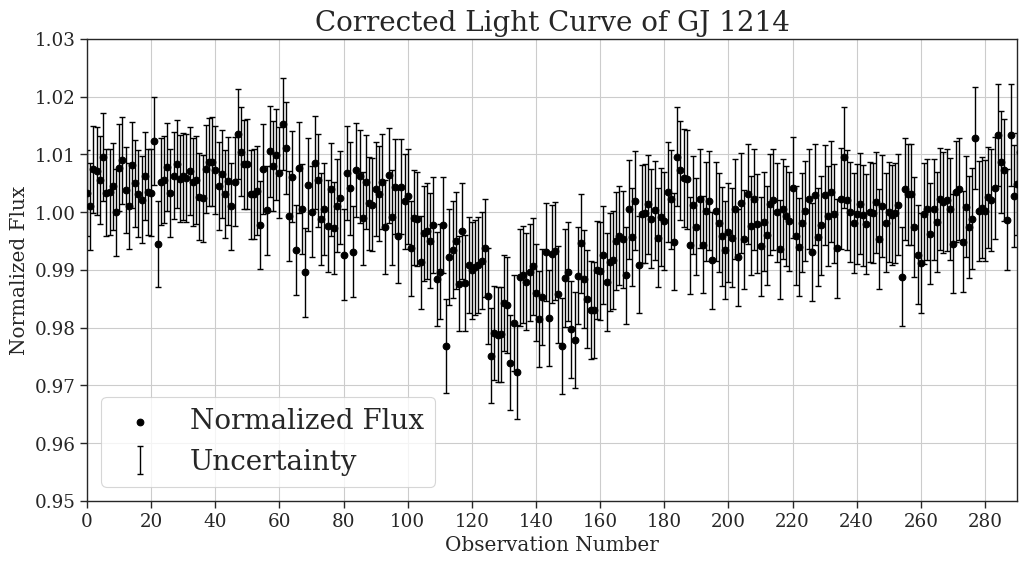

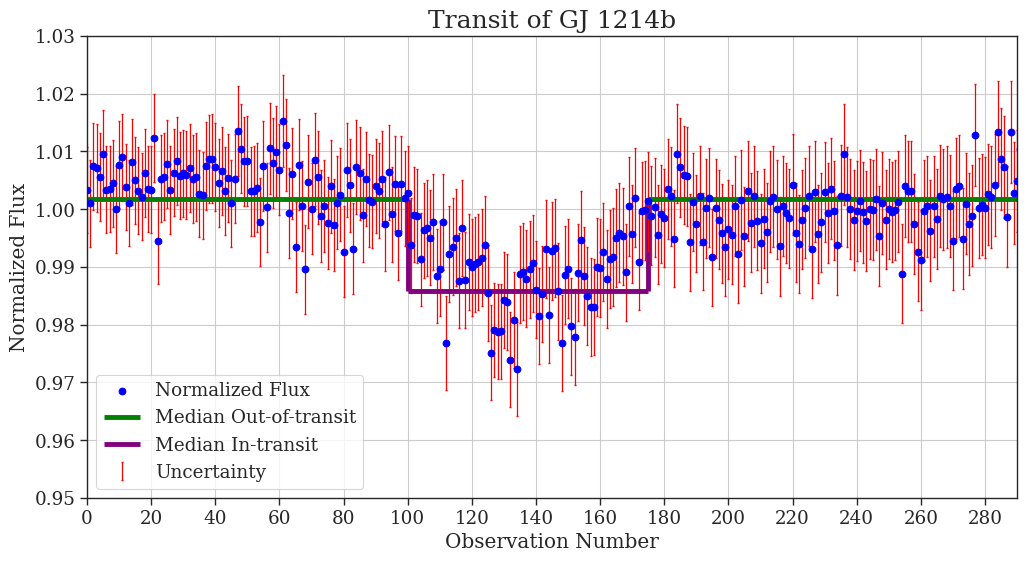

,Observation,centroid_x,centroid_y,flux,uncertainty,corrected_flux_median,corrected_flux_weighted,corrected_flux_mean_uncertainty
0,0,1418.511825,817.160739,17578.377345,140.316311,1.050143,1.003355,0.007477
1,1,1418.465362,817.927427,17850.420217,140.436999,1.044923,1.000997,0.007484
2,2,1418.793525,817.396996,18150.416006,141.448337,1.052535,1.007433,0.007536
3,3,1419.022005,817.307015,18174.274566,142.621024,1.062671,1.007111,0.007597
4,4,1418.517540,817.886850,18373.388286,142.328712,1.050799,1.005599,0.007582


In [249]:
from datetime import datetime

# Get the times from the headers
dates = [hdu['DATE-OBS'] for hdu in science_hdu]
times = [hdu['UTSTART'] for hdu in science_hdu]
datetime_strings = [f"{dates[i]} {times[i]}" for i in range(len(dates))]
datetimes = [datetime.strptime(s, "%Y-%m-%d %H:%M:%S.%f") for s in datetime_strings]
time_since_first_obs = [(dt - datetimes[0]).total_seconds() for dt in datetimes] # seconds
min_since_first_obs = [t/60 for t in time_since_first_obs] # minutes

# Apply reference curves to target star
# Median Reference
target_flux['corrected_flux_median'] = norm_target_flux / target_flux['Observation'].map(median_reference)
target_flux['corrected_flux_median'] = target_flux['corrected_flux_median'] / np.median(target_flux['corrected_flux_median'])

# Mean Reference
target_flux['corrected_flux_weighted'] = norm_target_flux / target_flux['Observation'].map(weighted_mean_reference)
target_flux['corrected_flux_weighted'] = target_flux['corrected_flux_weighted'] / np.median(target_flux['corrected_flux_weighted'])
target_flux['corrected_flux_mean_uncertainty'] = np.sqrt(norm_target_uncertainty**2 + weighted_mean_uncertainty**2)

fig = plt.figure(figsize=(12,6))
plt.title("Corrected Light Curve of GJ 1214", fontsize=20)
plt.xlabel("Observation Number")
plt.ylabel("Normalized Flux")
plt.xlim(0,290)
plt.xticks(np.arange(0, 300, 20))

plt.ylim(0.950, 1.03)
plt.errorbar(target_flux['Observation'], target_flux['corrected_flux_weighted'], label="Uncertainty", yerr=target_flux['corrected_flux_mean_uncertainty'], fmt='none', ecolor='black', elinewidth=1, capsize=2)
plt.scatter(target_flux['Observation'], target_flux['corrected_flux_weighted'], color='black', label="Normalized Flux",zorder=3)
plt.legend(fontsize=20)
plt.grid()
fig.savefig('plt/corrected_light_curve.pdf')
plt.show()

out_of_transit = target_flux[(target_flux['Observation'] < 100) | (target_flux['Observation'] > 180)]
median_out = np.median(out_of_transit['corrected_flux_weighted'])

in_transit = target_flux[(target_flux['Observation'] > 120) & (target_flux['Observation'] < 150)]
median_in = np.median(in_transit['corrected_flux_weighted'])

fig = plt.figure(figsize=(12,6))
plt.title("Transit of GJ 1214b", fontsize=18)
plt.xlabel("Observation Number")
plt.ylabel("Normalized Flux")
plt.xlim(0,290)
plt.ylim(0.950, 1.03)
plt.xticks(np.arange(0, 300, 20))
plt.errorbar(target_flux['Observation'], target_flux['corrected_flux_weighted'], yerr=target_flux['corrected_flux_mean_uncertainty'], fmt='none', ecolor='red', elinewidth=0.9, capsize=1, label="Uncertainty")
plt.scatter(target_flux['Observation'], target_flux['corrected_flux_weighted'], color='blue',label="Normalized Flux",zorder=3)

# Add horizontal lines at the median out-of-transit and in-transit flux levels
plt.hlines(median_out, 0, 100, colors='green', linestyles='solid', label='Median Out-of-transit', zorder=2, linewidth=3.5)
plt.hlines(median_out, 175, 290, colors='green', linestyles='solid', zorder=2, linewidth=3.5)
plt.hlines(median_in, 100, 175, colors='purple', linestyles='solid', label='Median In-transit', zorder=2, linewidth=3.5)
plt.vlines(100, median_out, median_in, colors='purple', linestyles='solid', zorder=1, linewidth=3.5)
plt.vlines(175, median_out, median_in, colors='purple', linestyles='solid', zorder=1, linewidth=3.5)
plt.grid()
plt.legend()
fig.savefig('plt/transit_estimate.pdf')
plt.show()

target_flux.head()


In [247]:
transit_depth = abs(median_in - median_out)  # values are already normalized
print(f"Change in flux during transit: {transit_depth*100:.2f}%")

star_radius = 0.216  # R sun
#star_radius_au = star_radius / 215  # AU
star_radius_au = 0.0010045009

# take square root of depth to calculate planet-star radius ratio
radius_ratio = np.sqrt(transit_depth) 

# multiply by star_radius to get estimated planet radius
estimated_radius = radius_ratio * star_radius
estimated_radius_au = radius_ratio * star_radius_au

print("Start of Transit: ", min_since_first_obs[100])
print("End of Transit: ", min_since_first_obs[175])
print("Duration of Transit: ", min_since_first_obs[175] - min_since_first_obs[100], "minutes")
print(f"Planet Star Ratio (R_p/R_s): {radius_ratio}")
print(f"Estimated Radius (Solar Radii): {estimated_radius}")
print(f"Estimated Radius (Jupiter Radii): {estimated_radius*9.95551486890475}")


Change in flux during transit: 1.59%
Start of Transit:  74.52399999999999
End of Transit:  129.29461666666666
Duration of Transit:  54.77061666666667 minutes
Planet Star Ratio (R_p/R_s): 0.12619210491784558
Estimated Radius (Solar Radii): 0.027257494662254644
Estimated Radius (Jupiter Radii): 0.27136239339916796


Limb Darkening

Radius: 2.9129175035742016 +/- 0.4024582652969209 Earth Radii
Semi-Major Axis: 9.745991290692697 +/- 1.4628920489207966 Solar Radii
Inclination: 90.95979639169371 +/- 0.29657036053246444 Degrees
Limb Darkening c1: 1.143079999999735 +/- 4.194258068444479
Limb Darkening c2: 0.6646443814638524 +/- 5.977577336130004


<>:100: SyntaxWarning: invalid escape sequence '\l'
<>:100: SyntaxWarning: invalid escape sequence '\l'
C:\Users\lwrig\AppData\Local\Temp\ipykernel_3192\4141000971.py:100: SyntaxWarning: invalid escape sequence '\l'
  fig.savefig('plt\limb.pdf')


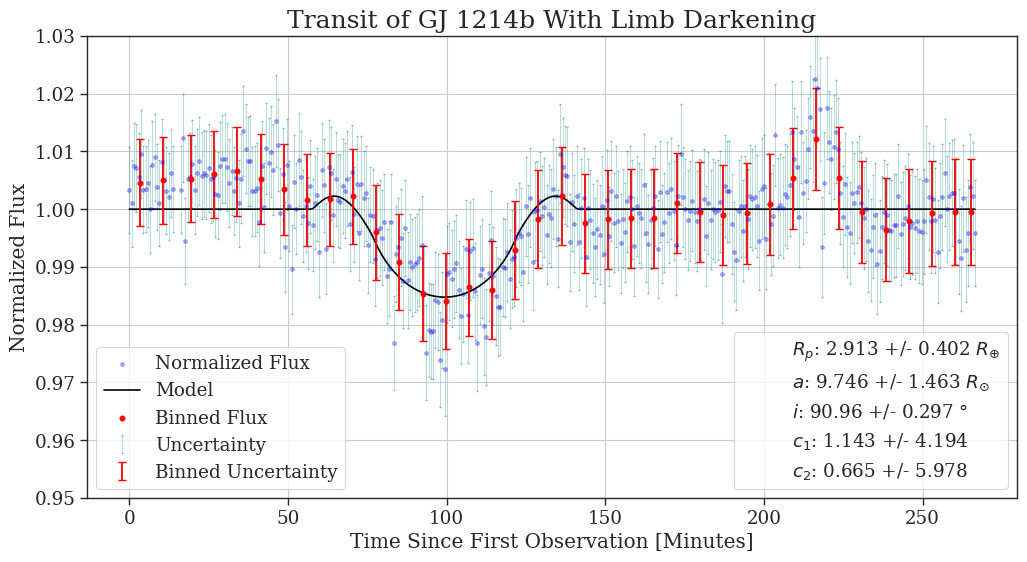

In [248]:
from occultquad import occultquad
from matplotlib.lines import Line2D

# Plot curve in days, binning by 8 observations

# Binned data
def bin_data(data, bin_size):
    binned_data = []
    for i in range(0, len(data), bin_size):
        binned_data.append(np.mean(data[i:i+bin_size]))
    return binned_data
bin_size = 10
binned_data = bin_data(target_flux['corrected_flux_weighted'], bin_size)
binned_positions = bin_data(min_since_first_obs, bin_size)
binned_uncertainty = bin_data(target_flux['corrected_flux_mean_uncertainty'], bin_size)
binned_data_np = np.array(binned_data)

##### Limb Darkening #####
# Taken from https://iopscience.iop.org/article/10.1088/0004-637X/731/2/123
# T_eff = 3026 +- 150. K 
#log_g = 4.94**0.22

# (Claret, 2004 Vizier), and exoplanet enc. 
c1 = .4065
c2 = .3753	
a = 0.01411  # AU
radius_guess = 0.0001169073322 # AU
orbital_period_minutes = 2275.78247568 # minutes

i=np.deg2rad(90)
time = min_since_first_obs[50:200]
# Find center of transit 
t_c_est = min_since_first_obs[np.where(target_flux['corrected_flux_weighted'] == np.min(target_flux['corrected_flux_weighted']))[0][0]]

def lc_model(time,r_p,a,i,c1,c2):
    def z(t):
        omega = 1 / orbital_period_minutes # rad/min
        return (a/star_radius_au)*(np.sqrt((np.sin(omega*t))**2 + (np.cos(i)*np.cos(omega*t))**2))

    curve_times = np.array(time) - t_c_est
    z_est = z(curve_times)
    radius_ratio = r_p / star_radius_au
    curve = occultquad(z_est,c1,c2,radius_ratio)[0]
    return curve
    

lower_bounds = [radius_guess - 0.01, a - 0.15,  i - .1, c1 - .4065, c2 - .3753]
upper_bounds = [radius_guess + 0.01, a + 0.15,  i + .1, c1 + .73658, c2 + 1]

popt, pcov = curve_fit(lc_model, time, target_flux['corrected_flux_weighted'][50:200], p0=[radius_guess,a,i,c1,c2], bounds=(lower_bounds, upper_bounds))
fit_error = np.array([np.sqrt(pcov[i,i]) for i in range(pcov.shape[0])])

print(f"Radius: {popt[0]*23450} +/- {fit_error[0]*23450} Earth Radii")
print(f"Semi-Major Axis: {popt[1]*215} +/- {fit_error[1]*215} Solar Radii")
print(f"Inclination: {np.rad2deg(popt[2])} +/- {np.rad2deg(fit_error[2])} Degrees")
print(f"Limb Darkening c1: {popt[3]} +/- {fit_error[3]}")
print(f"Limb Darkening c2: {popt[4]} +/- {fit_error[4]}")

fig = plt.figure(figsize=(12,6))
plt.title("Transit of GJ 1214b With Limb Darkening", fontsize=18)
plt.xlabel("Time Since First Observation [Minutes]")
plt.ylabel("Normalized Flux")
plt.errorbar(min_since_first_obs, target_flux['corrected_flux_weighted'], yerr=target_flux['corrected_flux_mean_uncertainty'], fmt='none', ecolor='teal', elinewidth=0.4, capsize=1, alpha = 0.5, label="Uncertainty")
plt.scatter(min_since_first_obs, target_flux['corrected_flux_weighted'], color='blue', alpha = 0.3, label="Normalized Flux",zorder=3, s=7)
plt.plot(min_since_first_obs, lc_model(min_since_first_obs,*popt), label="Model", color='black')
# Binned flux and uncertainty 
plt.scatter(binned_positions, binned_data, color='red',label=f"Binned Flux",zorder=3, s = 12)
plt.errorbar(binned_positions, binned_data, yerr=binned_uncertainty, fmt='none', ecolor='red', elinewidth=1.3, capsize=3, label="Binned Uncertainty")

#plt.xlim(0, 200)
plt.ylim(0.950, 1.03)
#plt.xticks(np.arange(0, 3.5, 0.5))
plt.grid()

first_legend = plt.legend(loc='lower left')
ax = plt.gca().add_artist(first_legend)
param_labels = [r'$R_p$', r'$a$', r'$i$', r'$c_1$', r'$c_2$']
param_values = [f'{np.round(popt[0]*23450,3)} +/- {np.round(fit_error[0]*23450,3)} {r'$R_{\oplus}$'}', f'{np.round(popt[1]*215,3)} +/- {np.round(fit_error[1]*215,3)} {r'$R_{\odot}$'}', f'{np.round(np.rad2deg(popt[2]),3)} +/- {np.round(np.rad2deg(fit_error[2]),3)} {r'$\degree$'}', f'{np.round(popt[3],3)} +/- {np.round(fit_error[3],3)}', f'{np.round(popt[4],3)} +/- {np.round(fit_error[4],3)}']
lines = [Line2D([0], [0], color='none', lw=2) for _ in range(len(param_labels))]
labels = [f'{lab}: {val}' for lab, val in zip(param_labels, param_values)]
second_legend = plt.legend(handles=lines, labels=labels, loc='lower right')
plt.show()
fig.savefig('plt\limb.pdf')
